In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import joblib
# import umap
from statistics import mean
from sklearn.metrics.pairwise import cosine_similarity

# locations of previously generated simulation data
SAVE_DIR = Path('~/ECM_mod_output').expanduser()
SAVE_DIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist  

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

# EMBED_DIR = Path(SAVE_DIR, 'UMAP/ODE_embeddings') # location of saved embedding files for each condition
EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition

SET_JPARAM = False # Set the parameters for the simulation

sys_type = sys.platform

output_from = 3 # 3: 03_ECM_model_output.ipynb 4: 04_Stoch_sims_for_UMAP.ipynb

if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

### Load specific ODE embeddings

`all_embedding_ode_conds_mac_from_04.sav` should have:
```
ODE_sim_DMSO_stiff_000_orig.csv
ODE_sim_DMSO_stiff_029_orig.csv
ODE_sim_DMSO_stiff_049_orig.csv
ODE_sim_DMSO_stiff_074_orig.csv
ODE_sim_DMSO_stiff_099_orig.csv
ODE_sim_ERL_stiff_000_orig.csv
ODE_sim_ERL_stiff_029_orig.csv
ODE_sim_ERL_stiff_049_orig.csv
ODE_sim_ERL_stiff_074_orig.csv
ODE_sim_ERL_stiff_099_orig.csv
```

`all_embedding_ode_conds_mac_from_03.sav` should be in the following order:
```
0, stiff_DMSO
1, stiff_ERL
2, int_DMSO
3, int_ERL
4, soft_DMSO
5, soft_ERL
```


Need 
```
embedding_ERL_range_000.csv
embedding_ERL_range_049.csv
embedding_ERL_range_099.csv
embedding_DMSO_range_000.csv
embedding_DMSO_range_029.csv
embedding_DMSO_range_074.csv
embedding_DMSO_range_099.csv
```



In [2]:
# These are the 6 experimental conditions that were simulated
all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_from_0{output_from}.sav')) # output of 05_UMAP_of_stoch_sims.ipynb (experimental conds)
all_embed_odes.shape

(12000, 2)

In [3]:
all_embed_stoch = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_from_0{output_from}.sav')) # output of 05_UMAP_of_stoch_sims.ipynb (experimental conds)
all_embed_stoch.shape

(239958, 2)

In [4]:
if output_from == 3:
    trk_len = 2000 # length of the trajectory
    trk_len_stoch = int(len(all_embed_stoch)/6)
elif output_from == 4:
    trk_len = 2000 # length of the trajectory (should be verified)
    trk_len_stoch = int(len(all_embed_stoch)/10) 

In [5]:
def get_traj(embed_dat, pos, trk_len=trk_len):
    if pos > len(embed_dat)/trk_len:
        print('Position out of range')
        return np.nan   
    embed_ode = embed_dat[pos*trk_len:(pos+1)*trk_len]
    return embed_ode


In [6]:
if output_from == 3:
    embed_array = np.concatenate(([get_traj(all_embed_odes,i) for i in (4,2,0,5,3,1,)])) # order the 6 experimental conditions
    embed_array_stoch = np.concatenate(([get_traj(all_embed_stoch,i,trk_len_stoch) for i in (4,2,0,5,3,1,)])) # order the 6 experimental conditions
elif output_from == 4:
    embed_array = np.concatenate(([get_traj(all_embed_odes,i) for i in (5,7,9,0,1,3,4,)])) # select the 7 conditions identified from Lyapunov analysis
    embed_array_stoch = np.concatenate(([get_traj(all_embed_stoch,i,trk_len_stoch) for i in (5,7,9,0,1,3,4,)])) # select the 7 conditions identified from Lyapunov analysis

In [7]:
# # These are the UMAP-embeddings of the ODE solutions of stiffnesses identified from the Lyapunov analysis
# filenames = ['embedding_erl_001.csv',
#              'embedding_erl_491.csv',
#              'embedding_erl_991.csv',
#              'embedding_dmso_0001.csv',
#              'embedding_dmso_0291.csv',
#              'embedding_dmso_0741.csv',
#              'embedding_dmso_0991.csv']

# embed_odes = [Path(EMBED_DIR,f) for f in os.listdir(EMBED_DIR) if f in filenames]
# embed_odes.sort()
# embed_odes

In [8]:
if output_from == 4:
    conds = ['0.0 DMSO', '0.3 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.5 ERL', '1.0 ERL',]
elif output_from == 3:
    conds = ['soft DMSO', 'int DMSO', 'stiff DMSO', 'soft ERL', 'int ERL', 'stiff ERL',]

### Load data

In [9]:
# embed_df = [pd.read_csv(f, header=None) for f in embed_odes]
# embed_array = pd.concat([pd.read_csv(f, header=None) for f in embed_odes], axis=0).to_numpy()
# l = int(embed_array.shape[0]/len(embed_odes))

# assert int(embed_df.shape[0]/len(embed_odes)) == embed_df.shape[0]/len(embed_odes)
# l = int(embed_df.shape[0]/len(embed_odes))


In [10]:
if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

In [11]:
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,7))
colors_accent = plt.cm.jet(np.linspace(0,1,7))

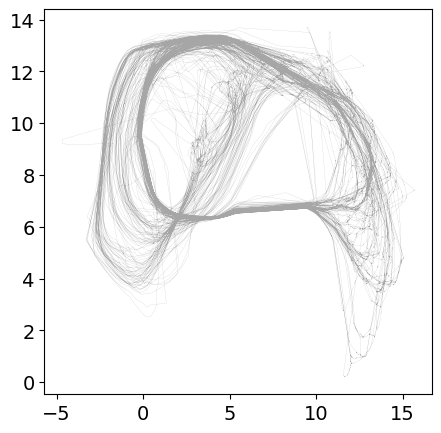

In [12]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

pos=5

plt.plot(embed_array_stoch[pos*trk_len_stoch:(pos+1)*trk_len_stoch,0], embed_array_stoch[pos*trk_len_stoch:(pos+1)*trk_len_stoch,1], 
         lw=0.1, alpha=0.7, c='gray')



### Plot figure


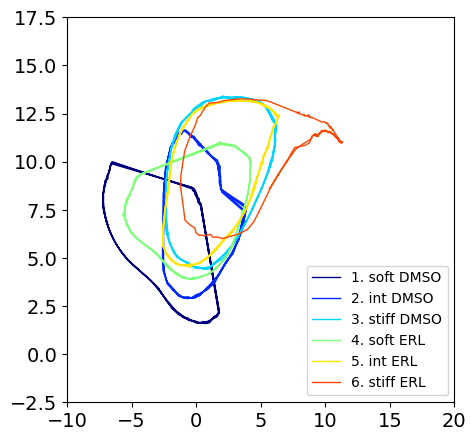

In [13]:
l = 2000

size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)


plt.xlim(-10,20)
plt.ylim(-2.5, 17.5)

if output_from == 3:
    for i in range(0,6):
        plt.plot(embed_array[(i*l):i*l+200,0], 
                 embed_array[(i*l):i*l+200,1], 
                 ls='-', lw=1, alpha=1, color=colors_accent[i], label=f'{i+1}. {conds[i]}')
elif output_from == 4:
    for i in range(0,7):
        plt.plot(embed_array[(i*l):i*l+150,0], 
                embed_array[(i*l):i*l+150,1], 
                ls='-', lw=1, alpha=1, color=colors_accent[i], label=f'{i+1}. {conds[i]}')

plt.legend()



### Plot another figure version

In [14]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,5))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

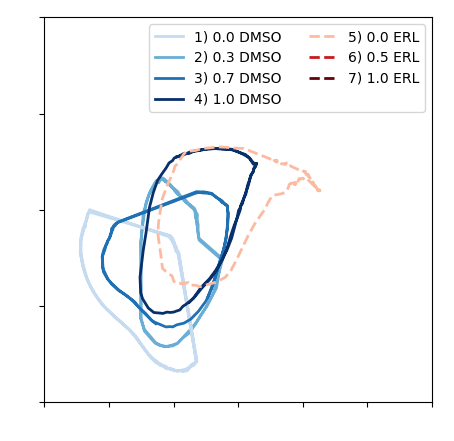

In [15]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

lw = 2


plt.plot(embed_array[1*l:1*l+100,0], 
         embed_array[1*l:1*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embed_array[0*l:0*l+150,0], 
         embed_array[0*l:0*l+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
plt.plot(embed_array[3*l:3*l+100,0], 
         embed_array[3*l:3*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
plt.plot(embed_array[4*l:4*l+100,0], 
         embed_array[4*l:4*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embed_array[5*l:5*l+150,0], 
         embed_array[5*l:5*l+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='5) 0.0 ERL')
plt.plot(embed_array[6*l:6*l+60,0], 
         embed_array[6*l:6*l+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) 0.5 ERL')
plt.plot(embed_array[7*l:7*l+55,0], 
         embed_array[7*l:7*l+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7) 1.0 ERL')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [1,0,2,3,4,5,6]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

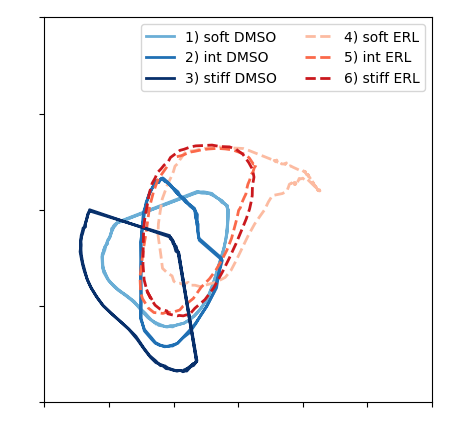

In [18]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

lw = 2

l = int(len(all_embed_odes)/6)
(5,7,9,0,1,3,4,)

plt.plot(embed_array[3*l:3*l+150,0], 
         embed_array[3*l:3*l+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='1) soft DMSO')
plt.plot(embed_array[5*l:5*l+150,0], 
         embed_array[5*l:5*l+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='4) soft ERL')
plt.plot(embed_array[1*l:1*l+100,0], 
         embed_array[1*l:1*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='2) int DMSO')
plt.plot(embed_array[4*l:4*l+60,0], 
         embed_array[4*l:4*l+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[2], label='5) int ERL')
plt.plot(embed_array[0*l:0*l+100,0], 
         embed_array[0*l:0*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='3) stiff DMSO')
plt.plot(embed_array[2*l:2*l+55,0], 
         embed_array[2*l:2*l+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) stiff ERL')




plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,2,4,1,3,5]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

In [17]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)


# what are these for?
n=0
n1=1


plt.plot(embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,0], 
         embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[0], label='1. DMSO_001')
plt.plot(embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,0], 
         embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[1], label='2. DMSO_025')
plt.plot(embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,0], 
         embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[2], label='3. DMSO_050')
plt.plot(embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,0], 
         embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[3], label='4. DMSO_075')
plt.plot(embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,0], 
         embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[4], label='5. DMSO_100')


plt.plot(embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode+120,0], 
         embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode+120,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[0], label='6. ERL_000')
plt.plot(embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode+120,0], 
         embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode+120,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[1], label='7. ERL_025')
plt.plot(embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode+70,0], 
         embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode+70,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[2], label='8. ERL_050')
plt.plot(embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode+55,0], 
         embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[3], label='9. ERL_075')
plt.plot(embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode+55,0], 
         embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[4], label='10. ERL_100')

plt.xlim(-10,20)
plt.ylim(-2.5, 17.5)

plt.legend()




NameError: name 'embedding_all_prot_ode' is not defined

<Figure size 500x500 with 0 Axes>

In [ ]:
[all_prot_tmp_conds, all_prot_tmp_ode_conds, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [ ]:
[all_prot_tmp_cycdi, all_prot_tmp_ode_cycdi, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_cycdi, filenames_ode_cycdi, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [ ]:
np.amax(all_prot_tmp_conds)

1.0

In [ ]:
# reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')
reducer = joblib.load('C:\\Users\\olesk\\ECM_mod_output\\reducer_03_20_0.1_0.1_4_0.5.sav')

In [ ]:
win_len = int(window/dt)

In [ ]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [ ]:
embedding_all_prot_conds = reducer.transform(all_prot_tmp_conds)

In [ ]:
embedding_all_prot_cycdi = reducer.transform(all_prot_tmp_cycdi)

In [ ]:
joblib.dump(embedding_all_prot_cycdi, "C:\\Users\\olesk\\data\\embedding_cycdi_0318.sav")
joblib.dump(all_prot_tmp_cycdi, "C:\\Users\\olesk\\data\\all_prot_cycdi_0318.sav")

['C:\\Users\\olesk\\data\\all_prot_cycdi_0318.sav']

In [ ]:
joblib.dump(embedding_all_prot_conds, "C:\\Users\\olesk\\data\\embedding_0318.sav")
joblib.dump(all_prot_tmp_conds, "C:\\Users\\olesk\\data\\all_prot_0318.sav")

['C:\\Users\\olesk\\data\\all_prot_0318.sav']

In [ ]:
all_prot_tmp.shape

(319944, 720)

In [ ]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
num_ts = int(all_prot_tmp_ode.shape[0]/w_len)

In [ ]:
w_len

39993.0

In [ ]:
all_prot_tmp_ode.shape

(319944, 720)

In [ ]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
sp = 1
for n in range(len(filenames_sp)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [ ]:
all_prot_tmp_ode_ab.shape

(16000, 720)

In [ ]:
win_len = int(window/dt)
all_prot_tmp_ode_ab_conds = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode_conds)/len(filenames_conds)
sp = 1
for n in range(len(filenames_conds)):
    tmp = all_prot_tmp_ode_conds[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab_conds = np.append(all_prot_tmp_ode_ab_conds, tmp, axis=0)
    sp += 1

In [ ]:
all_prot_tmp_ode_ab_conds.shape

(12000, 720)

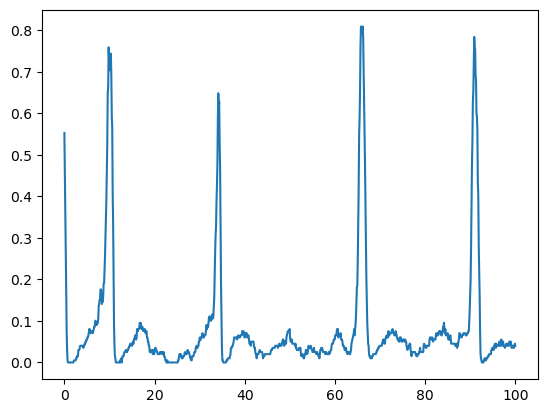

In [ ]:
plt.plot(np.linspace(0, 100, 1000), all_prot_tmp_cycdi[5*int(w_len):(5*int(w_len))+1000, 460])

In [ ]:
w_len

39993.0

In [ ]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [ ]:
embedding_all_prot_ode_conds = reducer.transform(all_prot_tmp_ode_ab_conds)

In [ ]:
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

In [ ]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,5))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

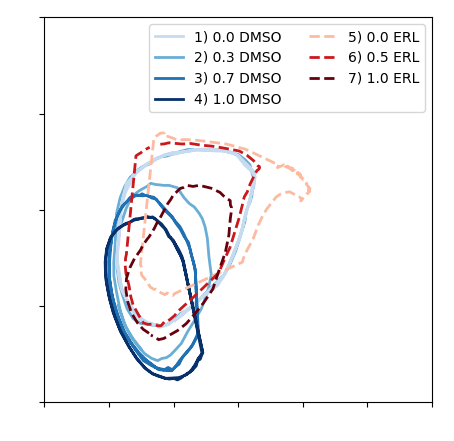

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1

lw = 2


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='5) 0.0 ERL')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) 0.5 ERL')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7) 1.0 ERL')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [1,0,2,3,4,5,6]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
# plt.legend(loc="upper right", ncol=2)


plt.savefig(str(SAVE_DIR)+"\\ODEs.svg", format="svg")


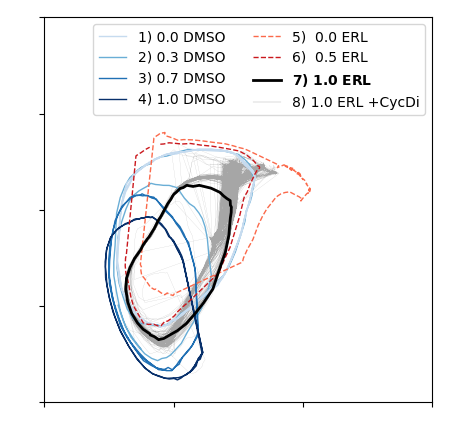

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=5
n1=6

plt.plot(embedding_all_prot_cycdi[n*trk_len:n1*trk_len,0], embedding_all_prot_cycdi[n*trk_len:n1*trk_len,1], 
         lw=0.1, alpha=0.7, c='gray', label='8) 1.0 ERL +CycDi')

# plt.plot(embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+140,0], 
#          embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+140,1], 
#          ls='-', lw=2, alpha=1, color='black', label='1.0 ERL')

lw=1
plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')

plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')

plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')

plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[2], label='5)  0.0 ERL')

plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6)  0.5 ERL')

plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='-', lw=2, alpha=1, color='black', label="$\\bf{7)\ 1.0\ ERL}$")

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [2,1,3,4,5,6,7,0]
leg = plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
for lh in leg.legendHandles: 
    lh.set_alpha(1)

leg.legendHandles[7].set_color('black')

plt.savefig(str(SAVE_DIR)+"\\ERL_100_cycdi_stoch_traj.svg", format="svg")


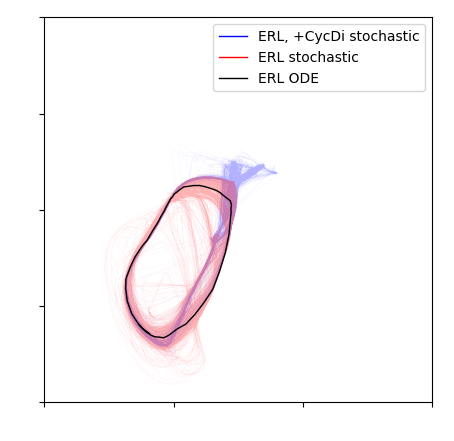

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=5
n1=6

plt.plot(embedding_all_prot_cycdi[n*trk_len:n1*trk_len,0], embedding_all_prot_cycdi[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.3, c='blue', label='ERL, +CycDi stochastic')

plt.plot(embedding_all_prot_conds[n*trk_len:n1*trk_len,0], embedding_all_prot_conds[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.3, c='red', label='ERL stochastic')

plt.plot(embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+57,0], 
         embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+57,1], 
         ls='-', lw=1, alpha=1, color='black', label='ERL ODE')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

leg = plt.legend()
for lh in leg.legendHandles:
    lh.set_alpha(1)
    lh.set_lw(1)

In [ ]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 30/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 30/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [ ]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

dmso_000_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_000_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_030_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_030_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_050_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_070_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_070_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_099_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_099_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_000_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])


In [ ]:
erl_099_cycdi_prot_df = pd.DataFrame(all_prot_tmp_cycdi[5*trk_len:6*trk_len,:])
erl_099_cycdi_time_df = pd.DataFrame(all_prot_tmp_cycdi[5*trk_len:6*trk_len,:])
erl_099_cycdi_emb_df = pd.DataFrame(embedding_all_prot_cycdi[5*trk_len:6*trk_len,:])

In [ ]:
erl_050_prot_df.shape

(39993, 720)

In [ ]:
from scipy.signal import find_peaks

In [ ]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [ ]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [ ]:
mit_win_erl_cycdi_099, time_win_erl_cycdi_099, umap_win_erl_cycdi_099 = restructProt(erl_099_cycdi_prot_df, erl_099_cycdi_emb_df, erl_099_cycdi_time_df)


In [ ]:
size = (4,4)
xmin = -10
xmax = 20
ymin = 0
ymax = 20
wid = 1
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
import scipy as sp

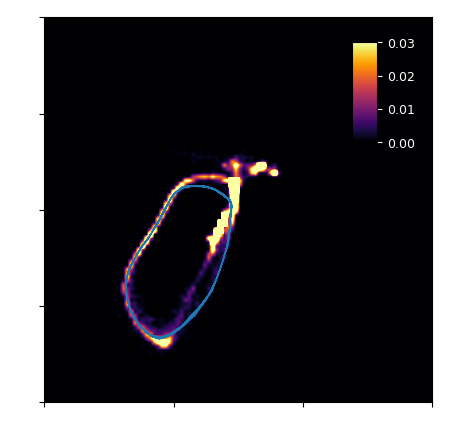

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_cycdi_099[0])
y = np.array(umap_win_erl_cycdi_099[1])
H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0



ax = fig.gca()

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                interpolation='bilinear', cmap='inferno', aspect='auto')
im.set_clim(0, 0.03)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1)

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.74, 0.63, 0.05, 0.2])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

plt.savefig(str(SAVE_DIR)+"\\ERL_100_cycdi_heatmap.svg", format="svg")


In [ ]:
sys.path.insert(0, "./../../../Vector_Similarity/python/TS_SS")
from Vector_Similarity import *

2.23606797749979
0.9999999999999998
0.0004639582566999478


In [ ]:
w_len = int(len(all_prot_tmp_ode)/len(filenames_sp))


In [ ]:
n=5
n1=6

# prot_vec=all_prot_tmp_conds[n*w_len:n1*w_len,:]
prot_vec=all_prot_tmp_cycdi[n*w_len:n1*w_len,:]
offset=1
v_len=1

In [ ]:
prot_inds = np.arange(n*w_len,n1*w_len,offset)

In [ ]:
prot_inds

array([199965, 199966, 199967, ..., 239955, 239956, 239957])

In [ ]:
def calc_sim(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp_conds[prot_inds[val]+v_len,:] - all_prot_tmp_conds[prot_inds[val],:]
        vec2=all_prot_tmp_conds[prot_inds[val+1]+v_len,:] - all_prot_tmp_conds[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [ ]:
def calc_sim_drug(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp_cycdi[prot_inds[val]+v_len,:] - all_prot_tmp_cycdi[prot_inds[val],:]
        vec2=all_prot_tmp_cycdi[prot_inds[val+1]+v_len,:] - all_prot_tmp_cycdi[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [ ]:
euc_vals, cos_vals, TS_SS_vals = calc_sim_drug(prot_vec, offset, v_len, prot_inds)

In [ ]:
euc_vals, cos_vals, TS_SS_vals = calc_sim(prot_vec, offset, v_len, prot_inds)

In [ ]:
log_euc_vals=[math.log(val) for val in euc_vals]
log_TS_SS_vals=[math.log(val) for val in TS_SS_vals]

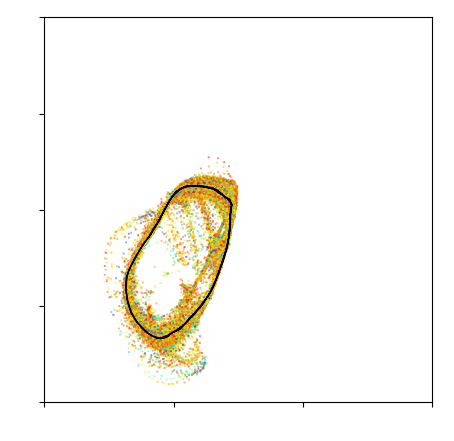

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

scatter1 = plt.scatter(embedding_all_prot_conds[prot_inds[:-2],0], embedding_all_prot_conds[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
plt.plot(tmp[500:650,0], tmp[500:650,1],
         lw=1, alpha=1, color='black')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

# cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
# cb = fig.colorbar(scatter1, cax=cbar_ax)
# cb.ax.tick_params(labelsize=9)

# cb.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

plt.savefig(str(SAVE_DIR)+"\\ERL_100_veccos.svg", format="svg")


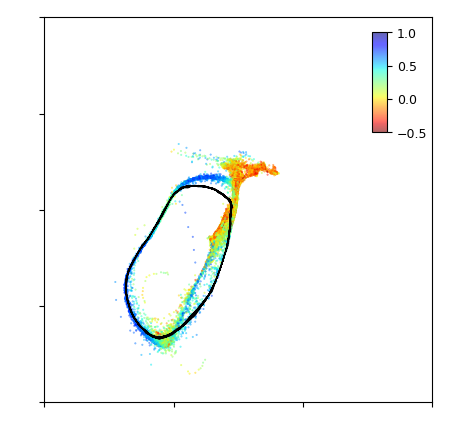

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

scatter1 = plt.scatter(embedding_all_prot_cycdi[prot_inds[:-2],0], embedding_all_prot_cycdi[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1, color='black')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
cb = fig.colorbar(scatter1, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)

# cb.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

plt.savefig(str(SAVE_DIR)+"\\ERL_100_cycdi_veccos.svg", format="svg")

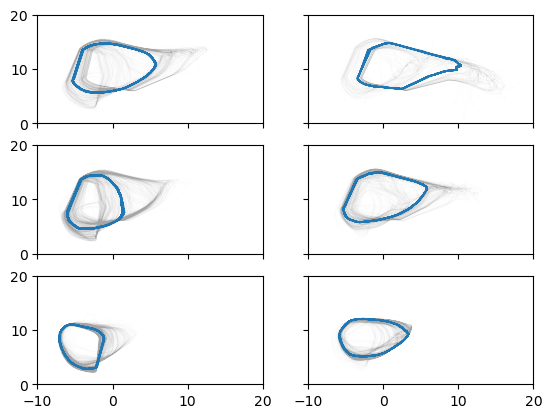

In [ ]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(embedding_all_prot)/9)
    trk_len_ode = int(len(embedding_all_prot_ode)/9)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

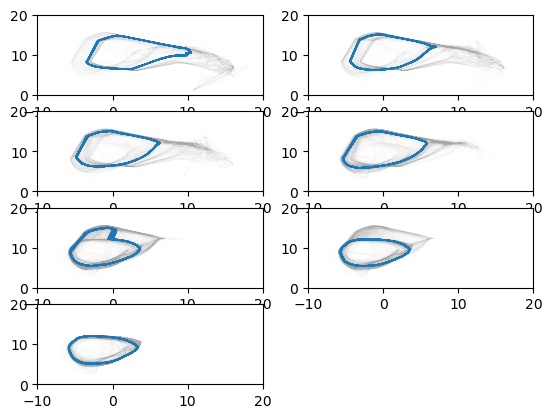

In [ ]:
fig = plt.figure()
n1 = 8
fign = 1
for n in range(7,14):
    plt.subplot(4,2,fign)
    trk_len = int(len(embedding_all_prot)/14)
    trk_len_ode = int(len(embedding_all_prot_ode)/14)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
#     if (n1 % 2) == 0:
#         ax.yaxis.set_tick_params(labelleft=False)
#     if n1<5:
#         ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1
    fign += 1

In [ ]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
dmso_050_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_007_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_007_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_007_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_023_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_023_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_023_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_045_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_045_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_045_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_085_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_085_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_085_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_006_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_006_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_006_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_076_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_076_time_df = pd.DataFrame(all_time_tmp[6*trk_len:7*trk_len,:])
erl_076_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_094_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_094_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_094_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

In [ ]:
trk_len = int(len(all_prot_tmp)/14)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_000_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

erl_020_prot_df = pd.DataFrame(all_prot_tmp[8*trk_len:9*trk_len,:])
erl_020_time_df = pd.DataFrame(all_time_tmp[8*trk_len:9*trk_len,:])
erl_020_emb_df = pd.DataFrame(embedding_all_prot[8*trk_len:9*trk_len,:])

erl_030_prot_df = pd.DataFrame(all_prot_tmp[9*trk_len:10*trk_len,:])
erl_030_time_df = pd.DataFrame(all_time_tmp[9*trk_len:10*trk_len,:])
erl_030_emb_df = pd.DataFrame(embedding_all_prot[9*trk_len:10*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[10*trk_len:11*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[10*trk_len:11*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[10*trk_len:11*trk_len,:])

erl_065_prot_df = pd.DataFrame(all_prot_tmp[11*trk_len:12*trk_len,:])
erl_065_time_df = pd.DataFrame(all_time_tmp[11*trk_len:12*trk_len,:])
erl_065_emb_df = pd.DataFrame(embedding_all_prot[11*trk_len:12*trk_len,:])

erl_070_prot_df = pd.DataFrame(all_prot_tmp[12*trk_len:13*trk_len,:])
erl_070_time_df = pd.DataFrame(all_time_tmp[12*trk_len:13*trk_len,:])
erl_070_emb_df = pd.DataFrame(embedding_all_prot[12*trk_len:13*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[13*trk_len:14*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[13*trk_len:14*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[13*trk_len:14*trk_len,:])

In [ ]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [ ]:
from scipy.signal import find_peaks
from numpy.linalg import norm
import multiprocess as mp
import time

In [ ]:
mit_win_dmso_060, time_win_dmso_060, umap_win_dmso_060 = restructProt(dmso_060_prot_df, dmso_060_emb_df, dmso_060_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)

In [ ]:
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_020, time_win_dmso_020, umap_win_dmso_020 = restructProt(dmso_020_prot_df, dmso_020_emb_df, dmso_020_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [ ]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_020, time_win_erl_020, umap_win_erl_020 = restructProt(erl_020_prot_df, erl_020_emb_df, erl_020_time_df)
mit_win_erl_030, time_win_erl_030, umap_win_erl_030 = restructProt(erl_030_prot_df, erl_030_emb_df, erl_030_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_065, time_win_erl_065, umap_win_erl_065 = restructProt(erl_065_prot_df, erl_065_emb_df, erl_065_time_df)
mit_win_erl_070, time_win_erl_070, umap_win_erl_070 = restructProt(erl_070_prot_df, erl_070_emb_df, erl_070_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [ ]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [ ]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_007, time_win_dmso_007, umap_win_dmso_007 = restructProt(dmso_007_prot_df, dmso_007_emb_df, dmso_007_time_df)
mit_win_dmso_023, time_win_dmso_023, umap_win_dmso_023 = restructProt(dmso_023_prot_df, dmso_023_emb_df, dmso_023_time_df)
mit_win_dmso_045, time_win_dmso_045, umap_win_dmso_045 = restructProt(dmso_045_prot_df, dmso_045_emb_df, dmso_045_time_df)
mit_win_dmso_085, time_win_dmso_085, umap_win_dmso_085 = restructProt(dmso_085_prot_df, dmso_085_emb_df, dmso_085_time_df)
mit_win_erl_006, time_win_erl_006, umap_win_erl_006 = restructProt(erl_006_prot_df, erl_006_emb_df, erl_006_time_df)
mit_win_erl_076, time_win_erl_076, umap_win_erl_076 = restructProt(erl_076_prot_df, erl_076_emb_df, erl_076_time_df)
mit_win_erl_094, time_win_erl_094, umap_win_erl_094 = restructProt(erl_094_prot_df, erl_094_emb_df, erl_094_time_df)

In [ ]:
def calc_distances(ode_proj, ode_wind, stoch_proj, stoch_wind, time_win):
    all_d_proj = []
    for row in range(len(stoch_proj)):
        difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
        min_d = min(difs)
        all_d_proj.append(min_d)
        if (row%10000) == 0:
            print(row)
    
    all_d = []
#     for n in time_win['div'].unique():
#         tmpDF = time_win.loc[time_win['div'] == n]
#         tmp = np.array(stoch_wind.iloc[tmpDF.iloc[0,3]:tmpDF.iloc[0,5],:])
#         tmp_umap = np.array(umapDF.iloc[tmpDF.index[0]:tmpDF.index[-1],:])
    for row in range(len(stoch_wind)):
        difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
        min_d = min(difs)
        all_d.append(min_d)
        if (row%10000) == 0:
            print(row)
        
    return all_d_proj, all_d

In [ ]:
ode_proj_umap = embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[7*trk_len_ode:7*trk_len_ode+200,:]
stoch_proj_umap = umap_win_dmso_050
stoch_wind = mit_win_dmso_050
time_win = time_win_dmso_050
rows = list(range(len(stoch_proj_umap)))


In [ ]:
def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [ ]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results_proj_d050_e094_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 12) as p:
    results_d050_e094_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)


229.30099391937256


In [ ]:
def plotDistHist(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', 
                         density=True, label=label)
    return his1
def plotDistHistCDF(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', density=True, 
                         cumulative=True, label=label)
    return his1

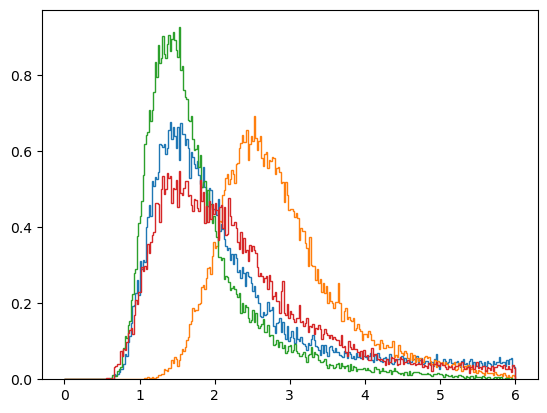

In [ ]:
his1= plotDistHist(results_d050_d050_wind, color='tab:blue')
his1= plotDistHist(results_d050_e050_wind, color='tab:orange')
his1= plotDistHist(results_d050_d030_wind, color='tab:green')
his1= plotDistHist(results_d050_d070_wind, color='tab:red')




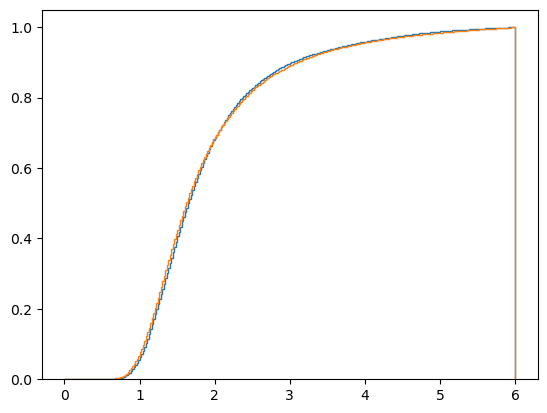

In [ ]:
his1= plotDistHistCDF(results_d065_d060_wind, color='tab:blue')
his1= plotDistHistCDF(results_d065_d070_wind, color='tab:orange')



In [ ]:
his1= plotDistHistCDF(results_060_wind, color='blue')
his1= plotDistHistCDF(results_060_072_wind, color='green')



In [ ]:
traj_dists = [results_e000_d000_wind, results_e000_e000_wind]
td_arr = np.array(traj_dists)

In [ ]:
def close_traj(traj_dists):
    num_trajs = list(range(len(traj_dists)))
    td_arr = np.array(traj_dists)  
    mins = []
    min_vals = []
    
    for traj in range(td_arr.shape[1]):
        mins.append(np.argmin(td_arr[:,traj]))
        min_vals.append(np.amin(td_arr[:,traj]))
        
    return mins, min_vals
            

In [ ]:
test, test_vals = close_traj(traj_dists)

In [ ]:
stoch_proj_umap['Closest'] = test

In [ ]:
stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

In [ ]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/14)
trk_len_ode = int(len(embedding_all_prot_ode)/14)
embedding_tmp = embedding_all_prot[0*trk_len:1*trk_len,:]
stoch_d00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]
stoch_e00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
plt.scatter(stoch_d00[0], stoch_d00[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e00[0], stoch_e00[1], s=0.2, alpha=0.1)
# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1)
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1)


plt.xlim(-10,20)
plt.ylim(0, 20)

KeyError: 'Closest'

<Figure size 640x480 with 0 Axes>

In [ ]:
len(stoch_d00)

2168

In [ ]:
traj_dists = [results_d050_d050_wind, results_d050_d007_wind, results_d050_d023_wind, 
              results_d050_d045_wind, results_d050_d085_wind, results_d050_e006_wind,
              results_d050_e076_wind, results_d050_e094_wind]
td_arr = np.array(traj_dists)


In [ ]:
test, test_vals = close_traj(traj_dists)


In [ ]:
stoch_proj_umap['Closest'] = test

(0.0, 20.0)

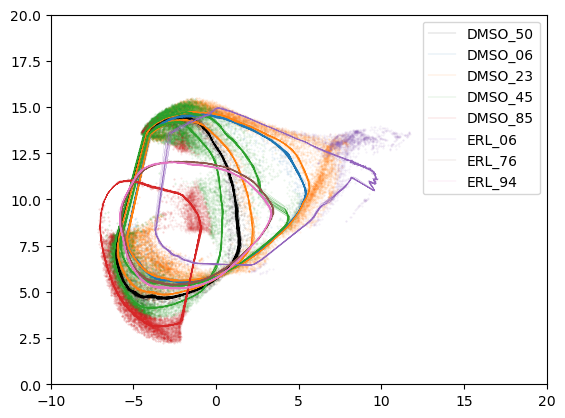

In [ ]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

stoch_d50 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

stoch_d07 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
stoch_d23 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 2]
stoch_d45 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 3]
stoch_d85 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 4]
stoch_e06 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 5]
stoch_e76 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 6]
stoch_e94 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 7]

plt.scatter(stoch_d50[0], stoch_d50[1], s=0.2, alpha=0.1, color='black')

plt.scatter(stoch_d07[0], stoch_d07[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d23[0], stoch_d23[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d45[0], stoch_d45[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d85[0], stoch_d85[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e06[0], stoch_e06[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e76[0], stoch_e76[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e94[0], stoch_e94[1], s=0.2, alpha=0.1)

# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1, color='black', label='DMSO_50')

plt.plot(embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,0], embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_06')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,0], embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_23')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,0], embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_45')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,0], embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_85')
plt.plot(embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,0], embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_06')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_76')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_94')

plt.legend()
plt.xlim(-10,20)
plt.ylim(0, 20)

In [ ]:
len(stoch_d50)

4909

In [ ]:
len(stoch_d07)

2133

In [ ]:
len(stoch_d23)

16503

In [ ]:
len(stoch_d45)

20154

In [ ]:
len(stoch_d85)

9164

In [ ]:
len(stoch_e06)

2019

In [ ]:
len(stoch_e76)

88

In [ ]:
len(stoch_e94)

64

In [ ]:
min7 = test_vals

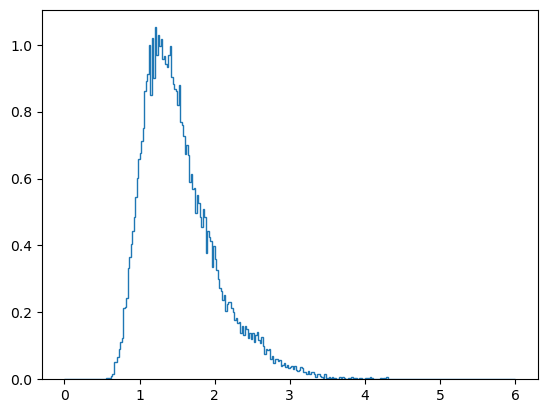

In [ ]:
his1= plotDistHist(min7, color='tab:blue')

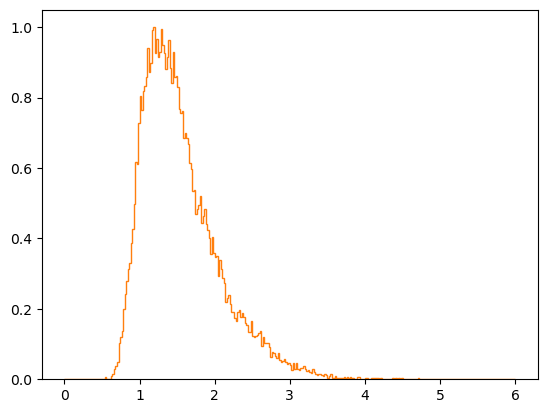

In [ ]:
his1= plotDistHist(test_vals, color='tab:orange')